# 停車場空位辨識：RBF Kernel SVM

此 Notebook 可從頭執行：**原始影片 → ROI / 雙遮罩 / 霍夫候選線 → 車格特徵 → C / gamma 搜尋 → RBF 推論 → MP4**。

將 `12125602_3840_2160_30fps.mp4` 放在 Notebook 同一資料夾，依序執行全部儲存格。也可以使用 Google Colab，上傳原始影片後設定 `VIDEO_PATH`。

- 內建本次鏡位設定、紅線 ROI 和人工核對標籤，無須另下載 `.py` 或模型。原始影片需自行提供，請勿使用已有框線的結果影片作輸入。
- 原標定 480 格；ROI 邊界覆蓋率不足 90% 的 1 格不參與統計，實際監測 **479 格**。
- 0、8、15、23 秒用於按時間分組的交叉驗證；29 秒先留出評估。評估完成後，才將所有已核對樣本重訓，用於這支固定影片。
- 留出畫面的準確率不代表整段影片每一幀皆正確，也不代表其他停車場的準確率。另比較逐格錯誤與空位數誤差，避免誤判互相抵銷。
- 即使不使用 GPU 也能執行；本例會完整處理 910 幀。

## 1. 安裝與匯入
只在套件不存在時安裝。`imageio-ffmpeg` 提供可攜的 H.264 編碼器；這個版本不依賴 Keras 或 scikit-learn。

In [10]:
import sys, subprocess, importlib.util
required = {"numpy": "numpy>=1.26,<2.3", "cv2": "opencv-python-headless>=4.10,<5",
            "PIL": "pillow", "imageio_ffmpeg": "imageio-ffmpeg>=0.5"}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import base64, csv, json, math, shutil, tempfile, time, zlib
from pathlib import Path
from types import SimpleNamespace
import cv2
import numpy as np
import imageio_ffmpeg
from PIL import Image
from IPython.display import display, HTML, Video
cv2.setNumThreads(2)
cv2.setRNGSeed(42)
FFMPEG_EXE = shutil.which("ffmpeg") or imageio_ffmpeg.get_ffmpeg_exe()
EMPTY, OCCUPIED, UNKNOWN = 0, 1, -1
GREEN, RED, AMBER, CYAN = (70,223,94), (65,85,239), (38,192,255), (245,211,48)
print("Python", sys.version.split()[0], "| OpenCV", cv2.__version__, "| NumPy", np.__version__)

Python 3.13.18 | OpenCV 4.14.0 | NumPy 2.1.3


## 2. 使用者設定
`VIDEO_PATH=None` 會尋找目前資料夾的原始影片；找不到時可改成完整路徑。輸出會建立在 `OUTPUT_DIR`。

`UNKNOWN_MARGIN` 是 SVM 決策值的門檻，不是機率。RBF 的決策值尺度與線性模型不同，這裡使用 0.20；較弱的空位判斷才參考霍夫分隔線，並保留約 0.3 秒的狀態確認時間。

In [11]:
INPUT_NAME = "停車場原始影像_30fps.mp4"
VIDEO_PATH = None   # 例如 Path("/content/12125602_3840_2160_30fps.mp4")
OUTPUT_DIR = Path(".").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_PATH = OUTPUT_DIR / "parking_rbf_result.mp4"
UNKNOWN_MARGIN = 0.20
STABILITY_SECONDS = 0.30
DETECT_EVERY, ALIGN_EVERY, HOUGH_EVERY = 3, 6, 6
OUTPUT_WIDTH = 1920
C_GRID = [0.1, 1.0, 10.0]
GAMMA_FACTORS = [0.1, 1.0, 10.0]  # gamma = factor / 795，作用於標準化後特徵
CV_AUGMENTATIONS = 2             # 含原圖：每個訓練樣本共 2 個版本
FINAL_AUGMENTATIONS = 3
EMBED_VIDEO = False              # True 可把影片嵌入 Notebook，但檔案會大幅增加

candidates = ([Path(VIDEO_PATH)] if VIDEO_PATH else
              [Path.cwd()/INPUT_NAME, Path.cwd()/"rbf_source"/INPUT_NAME,
               Path.cwd()/"upload"/INPUT_NAME, Path("/content")/INPUT_NAME])
VIDEO_PATH = None
for candidate in candidates:
    if not candidate.is_file():
        continue
    probe = cv2.VideoCapture(str(candidate))
    fps0, frames0 = probe.get(cv2.CAP_PROP_FPS), probe.get(cv2.CAP_PROP_FRAME_COUNT)
    width0, height0 = int(probe.get(cv2.CAP_PROP_FRAME_WIDTH)), int(probe.get(cv2.CAP_PROP_FRAME_HEIGHT))
    probe.release()
    if fps0 > 0 and frames0 / fps0 > 29.5:
        VIDEO_PATH = candidate.resolve()
        break
if VIDEO_PATH is None:
    raise FileNotFoundError("請提供完整約 30.36 秒的原始影片，並設定 VIDEO_PATH；不要使用片段或結果影片。")
SOURCE_FPS, SOURCE_FRAMES = float(fps0), int(frames0)
assert RESULT_PATH.resolve() != VIDEO_PATH.resolve(), "輸入與輸出不可是同一個檔案"
print(f"Source: {VIDEO_PATH.name} | {width0}x{height0} | {SOURCE_FRAMES} frames | {SOURCE_FPS:.5f} FPS")

Source: 停車場原始影像_30fps.mp4 | 3840x2160 | 910 frames | 29.97003 FPS


## 3. 內建鏡位設定
下列資料包含車格四角、紅線 ROI、對齊參考縮圖與原始線性基準權重。它沒有逐幀答案；時間標籤僅在後續訓練與評估時使用，影片推論仍從每次的新影像計算。

In [12]:
BUNDLED_PROFILE = '...'

def resize_frame(frame, size):
    return cv2.resize(frame, tuple(size), interpolation=cv2.INTER_AREA)

def load_profile(path=None):
    if path:
        profile = json.loads(Path(path).read_text(encoding="utf-8"))
    else:
        profile = json.loads(zlib.decompress(base64.b64decode(BUNDLED_PROFILE)))
    if profile.get("version") != 1:
        raise ValueError("Unsupported calibration version. Please recalibrate.")
    size = profile.get("analysis_size", [])
    if len(size) != 2 or min(size) < 100 or max(size) > 4096:
        raise ValueError("Invalid analysis_size in calibration.")
    slots = profile.get("slots", [])
    if not slots or len({s['id'] for s in slots}) != len(slots):
        raise ValueError("Calibration needs non-empty, uniquely named bays.")
    for slot in slots:
        polygon = np.asarray(slot["polygon"], np.float32)
        if (polygon.shape != (4, 2) or not np.isfinite(polygon).all()
                or not cv2.isContourConvex(polygon)
                or abs(cv2.contourArea(polygon)) < 12):
            raise ValueError(f"Invalid bay polygon: {slot.get('id')}")
    c = profile["classifier"]
    if (c.get("feature_version") != 1 or c.get("positive_class") != "empty"
            or np.asarray(c.get("weights")).shape != (795,)
            or not np.isfinite(c['weights']).all() or not math.isfinite(c['bias'])):
        raise ValueError("Invalid appearance classifier. Please recalibrate.")
    return profile

def make_roi_mask(profile):
    width, height = profile['analysis_size']
    polygon = profile.get('roi_polygon', [[0, 0], [width - 1, 0],
                         [width - 1, height - 1], [0, height - 1]])
    polygon = np.asarray(polygon, np.float32)
    if polygon.ndim != 2 or polygon.shape[1] != 2 or len(polygon) < 3 or not np.isfinite(polygon).all():
        raise ValueError('ROI needs at least three finite x/y points.')
    mask = np.zeros((height, width), np.uint8)
    cv2.fillPoly(mask, [np.rint(polygon).astype(np.int32)], 255)
    return mask

## 4. 畫面對齊、灰階遮罩與霍夫候選線
保留上一版紅線範圍：ROI 外以灰色呈現；第二遮罩排除範圍外、車道及非漆線附近的邊緣。Canny/Hough 實際在裁切停車列中執行。

霍夫參數採 `rho=1 pixel`、`theta=1 degree`、`threshold=18`、`minLineLength=24 pixels`、`maxLineGap=5 pixels`。**minLineLength 是線段長度，maxLineGap 才是斷裂間距。**霍夫直線是幾何證據，不代表線段旁一定有空位。

In [13]:
class CameraAlignment:
    """Reference-to-current homography with quality gates; fail to UNKNOWN."""
    def __init__(self, profile):
        self.size = tuple(profile["analysis_size"])
        self.track_size = (960, round(960 * self.size[1] / self.size[0]))
        thumbnail = np.frombuffer(base64.b64decode(profile["reference_jpeg_base64"]), np.uint8)
        ref = cv2.imdecode(thumbnail, cv2.IMREAD_COLOR)
        if ref is None:
            raise ValueError("Cannot decode calibration reference image.")
        gray = cv2.cvtColor(resize_frame(ref, self.track_size), cv2.COLOR_BGR2GRAY)
        self.orb = cv2.ORB_create(nfeatures=2800, fastThreshold=12)
        self.roi_mask = make_roi_mask(profile)
        reference_mask = cv2.resize(self.roi_mask,self.track_size,interpolation=cv2.INTER_NEAREST)
        self.kp, self.des = self.orb.detectAndCompute(gray, reference_mask)
        if self.des is None or len(self.kp) < 40:
            raise ValueError("Reference has insufficient features for alignment.")
        self.matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
        self.h = np.eye(3)
        self.ok = False
        self.inliers = 0

    def update(self, frame):
        gray = cv2.cvtColor(resize_frame(frame, self.track_size), cv2.COLOR_BGR2GRAY)
        current_mask = cv2.warpPerspective(self.roi_mask,self.h,self.size,flags=cv2.INTER_NEAREST)
        current_mask = cv2.resize(current_mask,self.track_size,interpolation=cv2.INTER_NEAREST)
        kp, des = self.orb.detectAndCompute(gray, current_mask)
        self.ok, self.inliers = False, 0
        if des is None or len(kp) < 40:
            return False
        pairs = self.matcher.knnMatch(self.des, des, k=2)
        good = [pair[0] for pair in pairs if len(pair) == 2
                and pair[0].distance < .73 * pair[1].distance]
        if len(good) < 35:
            return False
        a = np.float32([self.kp[m.queryIdx].pt for m in good])
        b = np.float32([kp[m.trainIdx].pt for m in good])
        h, mask = cv2.findHomography(a, b, cv2.RANSAC, 2.5)
        if h is None or mask is None or not np.isfinite(h).all():
            return False
        self.inliers = int(mask.sum())
        if self.inliers < 30 or self.inliers / len(good) < .4:
            return False
        inlier = mask.ravel().astype(bool)
        errors = np.linalg.norm(cv2.perspectiveTransform(a[None], h)[0] - b, axis=1)
        if np.median(errors[inlier]) > 2:
            return False
        tw, th = self.track_size
        corners = np.float32([[0, 0], [tw - 1, 0], [tw - 1, th - 1], [0, th - 1]])
        mapped = cv2.perspectiveTransform(corners[None], h)[0]
        ratio = abs(cv2.contourArea(mapped)) / (tw * th)
        if (not cv2.isContourConvex(mapped) or not .65 < ratio < 1.5
                or np.max(np.linalg.norm(mapped - corners, axis=1)) > .3 * tw):
            return False
        S = np.diag([self.size[0] / tw, self.size[1] / th, 1.0])
        self.h = S @ h @ np.linalg.inv(S)
        self.ok = True
        return True

class MaskedHoughPreprocessor:
    """Two masks + cropped probabilistic Hough, with conservative occupancy review.

    Mask 1: ROI gray mask; outside the user's outline is excluded.
    Mask 2: eroded ROI AND bay search bands AND paint-neighbourhood edges.
    Canny/Hough run on cropped parking islands, not a zero-filled full frame.
    Hough finds geometry, not cars. It can withhold a weak EMPTY prediction
    lacking divider support; it never changes an OCCUPIED prediction to EMPTY.
    """
    def __init__(self, profile, args):
        self.size = tuple(profile['analysis_size'])
        self.slots = profile['slots']
        self.polygons = np.float32([s['polygon'] for s in self.slots])
        self.args = args
        self.roi_mask = make_roi_mask(profile)
        self.safe_roi = cv2.erode(self.roi_mask, np.ones((7, 7), np.uint8))
        bay_mask = np.zeros_like(self.roi_mask)
        boundary = np.zeros_like(bay_mask)
        for p in self.polygons:
            cv2.fillConvexPoly(bay_mask, np.rint(p).astype(np.int32), 255)
            cv2.polylines(boundary, [np.rint(p).astype(np.int32)], True, 255, 11)
        expanded = cv2.dilate(bay_mask, np.ones((9, 9), np.uint8))
        self.edge_mask = cv2.bitwise_and(expanded, self.safe_roi)
        self.boundary_mask = boundary
        # Connected islands skip traffic lanes, landscaping and the top strip.
        n, labels, stats, centers = cv2.connectedComponentsWithStats(expanded)
        self.tiles = []
        for x, y, w, h, area in stats[1:]:
            if area < 30:
                continue
            x0, y0 = max(0, int(x) - 2), max(0, int(y) - 2)
            x1, y1 = min(self.size[0], int(x + w) + 2), min(self.size[1], int(y + h) + 2)
            self.tiles.append((x0, y0, x1, y1))
        self.canny_pixels = sum((x1-x0)*(y1-y0) for x0,y0,x1,y1 in self.tiles)
        self.roi_coverage = np.array([self._bay_coverage(p) for p in self.polygons])
        self.support = np.zeros(len(self.slots), np.int8)
        self.side_coverage = np.zeros((len(self.slots), 2), np.float32)
        self.lines = np.empty((0, 4), np.float32)
        self.edges = np.zeros_like(bay_mask)
        self.gray_masked = np.zeros_like(bay_mask)
        self.vertical_lines = np.zeros_like(bay_mask)
        self.last_ms = 0.
        self.raw_line_count = 0
        self.last_reviewed = np.zeros(len(self.slots), bool)
        self.history_ms = []
        self.generation=0
        self.display_cache_key=None
        # Samples on each side divider, keeping away from row-end intersections.
        tt = np.linspace(.08, .92, 32, dtype=np.float32)
        sample = []
        for p in self.polygons:
            sample.append(np.array([p[0] + tt[:, None] * (p[3]-p[0]),
                                    p[1] + tt[:, None] * (p[2]-p[1])]))
        sample = np.asarray(sample, np.float32)
        self.sample_x = sample[:, :, :, 0].reshape(-1, 32)
        self.sample_y = sample[:, :, :, 1].reshape(-1, 32)

    def _bay_coverage(self, polygon):
        x, y, w, h = cv2.boundingRect(polygon)
        x0, y0 = max(0, x), max(0, y)
        x1, y1 = min(self.size[0], x+w), min(self.size[1], y+h)
        if x1 <= x0 or y1 <= y0:
            return 0.
        local = np.zeros((y1-y0, x1-x0), np.uint8)
        cv2.fillConvexPoly(local, np.rint(polygon-[x0,y0]).astype(np.int32), 255)
        selected = local > 0
        return float(np.mean(self.roi_mask[y0:y1,x0:x1][selected] > 0)) if selected.any() else 0.

    def process(self, aligned):
        started = time.perf_counter()
        gray = cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY)
        # This is the actual gray ROI image; masking follows grayscale conversion.
        self.gray_masked = cv2.bitwise_and(gray, gray, mask=self.roi_mask)
        self.edges.fill(0)
        accepted, raw_count = [], 0
        for x0, y0, x1, y1 in self.tiles:
            g = gray[y0:y1, x0:x1]
            smoothed = cv2.GaussianBlur(g, (3,3), 0)
            # Detect edges BEFORE applying masks, avoiding an artificial ROI edge.
            canny = cv2.Canny(smoothed, self.args.canny_low, self.args.canny_high)
            hsv = cv2.cvtColor(aligned[y0:y1,x0:x1], cv2.COLOR_BGR2HSV)
            paint = np.uint8((g >= 145) & (hsv[:,:,1] <= 120))*255
            paint = cv2.dilate(paint, np.ones((3,3),np.uint8))
            filtered = cv2.bitwise_and(canny, self.edge_mask[y0:y1,x0:x1])
            filtered = cv2.bitwise_and(filtered, paint)
            self.edges[y0:y1,x0:x1] = cv2.bitwise_or(self.edges[y0:y1,x0:x1], filtered)
            if self.args.no_hough:
                continue
            found = cv2.HoughLinesP(filtered, rho=self.args.rho,
                        theta=np.deg2rad(self.args.theta), threshold=self.args.hough_threshold,
                        minLineLength=self.args.min_line_length, maxLineGap=self.args.max_line_gap)
            if found is None:
                continue
            raw_count += len(found)
            lines=found.reshape(-1,4).astype(np.float32)+[x0,y0,x0,y0]
            dx,dy=lines[:,2]-lines[:,0],lines[:,3]-lines[:,1]
            angle=np.abs(np.degrees(np.arctan2(dy,dx)))%180
            eligible=(np.abs(angle-90)<=12)|(np.minimum(angle,180-angle)<=12)
            lines=lines[eligible]
            if not len(lines):
                continue
            tt=np.linspace(0,1,25,dtype=np.float32)[None,:]
            xx=np.rint(lines[:,0,None]+(lines[:,2]-lines[:,0])[:,None]*tt).astype(int)
            yy=np.rint(lines[:,1,None]+(lines[:,3]-lines[:,1])[:,None]*tt).astype(int)
            # Vectorized geometry prior, avoiding a Python loop per Hough line.
            keep=np.mean(self.boundary_mask[yy,xx]>0,axis=1)>=.7
            accepted.extend(lines[keep])
        self.raw_line_count = raw_count
        self.lines = np.asarray(accepted,np.float32).reshape(-1,4)
        self.vertical_lines.fill(0)
        for x1,y1,x2,y2 in self.lines:
            if abs(y2-y1) > abs(x2-x1)*2:
                cv2.line(self.vertical_lines,(round(x1),round(y1)),(round(x2),round(y2)),255,1)
        near = cv2.dilate(self.vertical_lines,np.ones((3,9),np.uint8))
        samples = cv2.remap(near,self.sample_x,self.sample_y,cv2.INTER_NEAREST,
                            borderMode=cv2.BORDER_CONSTANT)
        self.side_coverage = np.mean(samples.reshape(-1,2,32)>0,axis=2)
        self.support = (self.side_coverage >= .35).sum(axis=1).astype(np.int8)
        self.last_ms = (time.perf_counter()-started)*1000
        self.history_ms.append(self.last_ms)
        self.generation+=1

    def review(self, prediction, confidence):
        confidence = confidence.copy()
        self.last_reviewed = np.zeros(len(prediction),bool)
        if not self.args.no_hough:
            self.last_reviewed = ((prediction == EMPTY)
                & (confidence >= self.args.margin)
                & (confidence < self.args.hough_review_margin)
                & (self.support < self.args.hough_min_sides))
            confidence[self.last_reviewed] = 0
        return confidence

    def info(self, states):
        return {'lines':len(self.lines), 'raw_lines':self.raw_line_count,
                'supported_empty':int(((states==EMPTY)&(self.support>0)).sum()),
                'reviewed_empty':int(self.last_reviewed.sum()),
                'edge_area_pct':100*self.canny_pixels/self.roi_mask.size}

    def paint_scene(self, scene, h_display, show_lines=True):
        h,w = scene.shape[:2]
        key=(w,h,h_display.tobytes(),self.generation,bool(show_lines))
        if key!=self.display_cache_key:
            mask=cv2.warpPerspective(self.roi_mask,h_display,(w,h),flags=cv2.INTER_NEAREST)
            self.excluded_display=mask==0
            layer=np.zeros_like(scene)
            if show_lines and len(self.lines):
                pairs=self.lines.reshape(-1,2,2)
                mapped=cv2.perspectiveTransform(pairs,h_display)
                for pair in mapped:
                    cv2.line(layer,tuple(np.rint(pair[0]).astype(int)),
                             tuple(np.rint(pair[1]).astype(int)),CYAN,1,cv2.LINE_AA)
            self.line_display_pixels=np.any(layer!=0,axis=2)
            self.line_display_colors=layer[self.line_display_pixels]
            self.display_polygon=np.rint(cv2.perspectiveTransform(np.float32(self.args.roi_polygon)[None],h_display)[0]).astype(np.int32)
            self.display_cache_key=key
        # Gray overlay on the original image explicitly shows excluded pixels.
        scene[self.excluded_display] = (115,115,115)
        scene[self.line_display_pixels]=self.line_display_colors
        cv2.polylines(scene,[self.display_polygon],True,(80,160,250),2,cv2.LINE_AA)
        return scene

    def save_debug(self, aligned, states, path):
        source = aligned.copy()
        source[self.roi_mask==0] = (115,115,115)
        cv2.polylines(source,[np.rint(self.args.roi_polygon).astype(np.int32)],True,(60,100,245),3)
        gray = cv2.cvtColor(self.gray_masked,cv2.COLOR_GRAY2BGR)
        edge = cv2.cvtColor(self.edges,cv2.COLOR_GRAY2BGR)
        detection = aligned.copy()
        detection[self.roi_mask==0] = (115,115,115)
        for x1,y1,x2,y2 in self.lines:
            cv2.line(detection,(round(x1),round(y1)),(round(x2),round(y2)),CYAN,1,cv2.LINE_AA)
        for poly,state in zip(self.polygons,states):
            cv2.polylines(detection,[np.rint(poly).astype(np.int32)],True,
                          GREEN if state==EMPTY else RED if state==OCCUPIED else AMBER,1)
        panels=[]
        for im,title in [(source,'1  ORIGINAL + GRAY EXCLUSION MASK'),
                          (gray,'2  GRAYSCALE ROI MASK'),
                          (edge,'3  FILTERED CANNY EDGES (CROPPED ISLANDS)'),
                          (detection,'4  HOUGH DIVIDERS + OCCUPANCY')]:
            im=cv2.resize(im,(960,540),interpolation=cv2.INTER_AREA)
            tile=np.full((586,960,3),(24,24,24),np.uint8)
            tile[46:]=im
            cv2.putText(tile,title,(16,30),0,.57,(240,240,240),1,cv2.LINE_AA)
            panels.append(tile)
        sheet=np.vstack([np.hstack(panels[:2]),np.hstack(panels[2:])])
        footer=np.full((66,1920,3),(24,24,24),np.uint8)
        label=(f'rho={self.args.rho:g}px   theta={self.args.theta:g}deg   votes={self.args.hough_threshold}   '
               f'minLineLength={self.args.min_line_length:g}px   maxLineGap={self.args.max_line_gap:g}px   '
               f'Canny crop area={100*self.canny_pixels/self.roi_mask.size:.1f}%')
        cv2.putText(footer,label,(20,40),0,.63,(220,230,235),1,cv2.LINE_AA)
        sheet=np.vstack([sheet,footer])
        Path(path).parent.mkdir(parents=True,exist_ok=True)
        if not cv2.imwrite(str(path),sheet,[cv2.IMWRITE_JPEG_QUALITY,95]):
            raise RuntimeError('Cannot write preprocessing debug image.')

## 5. 車格特徵與 RBF 訓練函式
每格內縮後取樣成 32×64。輸入為 756 個 HOG、32 個粗略亮度分布及 7 個統計特徵，共 795 維。

每個交叉驗證折只用訓練畫面估計 mean/std，將相同縮放套用到該折驗證畫面。`C_SVC` 本身使用 Soft Margin；C 與 gamma 的組合由實際驗證選擇。

In [14]:
class FeatureBatch:
    """Extract all bay interiors with one remap; no deep-learning dependencies."""
    def __init__(self, slots):
        self.n = len(slots)
        self.hog = cv2.HOGDescriptor((32, 64), (16, 16), (8, 8), (8, 8), 9)
        yy, xx = np.mgrid[:64, :32].astype(np.float32)
        dest = np.float32([[0, 0], [31, 0], [31, 63], [0, 63]])
        maps = []
        for slot in slots:
            q = np.asarray(slot["polygon"], np.float32)
            left, right = q[0] * .82 + q[1] * .18, q[0] * .18 + q[1] * .82
            bl, br = q[3] * .82 + q[2] * .18, q[3] * .18 + q[2] * .82
            # Inset excludes paint dividers and small neighbouring-car overlaps.
            inner = np.float32([left * .9 + bl * .1, right * .9 + br * .1,
                                right * .1 + br * .9, left * .1 + bl * .9])
            h = cv2.getPerspectiveTransform(dest, inner)
            den = h[2, 0] * xx + h[2, 1] * yy + h[2, 2]
            mx = (h[0, 0] * xx + h[0, 1] * yy + h[0, 2]) / den
            my = (h[1, 0] * xx + h[1, 1] * yy + h[1, 2]) / den
            maps.append((mx.astype(np.float32), my.astype(np.float32)))
        self.mx = np.vstack([m[0] for m in maps])
        self.my = np.vstack([m[1] for m in maps])

    def patches(self, frame):
        p = cv2.remap(frame, self.mx, self.my, cv2.INTER_LINEAR,
                      borderMode=cv2.BORDER_REFLECT_101)
        return p.reshape(self.n, 64, 32, 3)

    @staticmethod
    def describe(patches, hog):
        n = len(patches)
        p = np.ascontiguousarray(patches).reshape(n * 64, 32, 3)
        g = cv2.cvtColor(p, cv2.COLOR_BGR2GRAY)
        gray = g.reshape(n, 64, 32)
        hsv = cv2.cvtColor(p, cv2.COLOR_BGR2HSV).reshape(n, 64, 32, 3)
        h = np.array([hog.compute(gg).ravel() for gg in gray])
        small = cv2.resize(g, (4, n * 8), interpolation=cv2.INTER_AREA)
        small = small.reshape(n, 8, 4).astype(np.float32)
        structure = ((small - small.mean(axis=(1, 2))[:, None, None]) / 64).reshape(n, -1)
        edge = np.array([np.mean(cv2.Canny(cv2.GaussianBlur(gg, (3, 3), 0),
                                         45, 100) > 0) for gg in gray])
        q10, q90 = np.percentile(gray, [10, 90], axis=(1, 2))
        summary = np.column_stack([
            gray.std(axis=(1, 2)) / 50, (q90 - q10) / 140, edge * 5,
            hsv[:, :, :, 1].mean(axis=(1, 2)) / 100,
            (gray < 65).mean(axis=(1, 2)) * 2,
            (gray > 195).mean(axis=(1, 2)) * 2, gray.mean(axis=(1, 2)) / 255])
        return np.concatenate([h, structure, summary], axis=1).astype(np.float32)

    def features(self, frame):
        return self.describe(self.patches(frame), self.hog)

"""RBF learning and frame-grouped validation; also embedded readably in the notebook."""
import json,time
from pathlib import Path
import cv2,numpy as np

def augment_patches(patches,repeats,seed=42):
    rng=np.random.default_rng(seed)
    out=[]
    for patch in patches:
        out.append(patch)
        for j in range(repeats-1):
            M=cv2.getRotationMatrix2D((15.5,31.5),float(rng.uniform(-2,2)),1.)
            M[:,2]+=rng.uniform([-1.2,-1.4],[1.2,1.4])
            x=cv2.warpAffine(patch,M,(32,64),borderMode=cv2.BORDER_REFLECT_101)
            x=np.clip(x.astype(np.float32)*rng.uniform(.85,1.15)+rng.uniform(-6,6),0,255).astype(np.uint8)
            out.append(x)
    return np.asarray(out,np.uint8)

def describe_many(patches,FeatureBatch,chunk=200):
    hog=cv2.HOGDescriptor((32,64),(16,16),(8,8),(8,8),9)
    return np.concatenate([FeatureBatch.describe(patches[i:i+chunk],hog)
                           for i in range(0,len(patches),chunk)])

def standardizer(X):
    mean=X.mean(axis=0,dtype=np.float64).astype(np.float32)
    scale=X.std(axis=0,dtype=np.float64).astype(np.float32)
    scale[scale<1e-6]=1.
    return mean,scale

def transform(X,mean,scale):
    return np.ascontiguousarray((X-mean)/scale,np.float32)

def fit_svm(X,y,kernel,C,gamma=None):
    model=cv2.ml.SVM_create()
    model.setType(cv2.ml.SVM_C_SVC)
    model.setKernel(cv2.ml.SVM_RBF if kernel=='rbf' else cv2.ml.SVM_LINEAR)
    model.setC(float(C))
    if kernel=='rbf':model.setGamma(float(gamma))
    model.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER|cv2.TERM_CRITERIA_EPS,20000,1e-6))
    if not model.train(X,cv2.ml.ROW_SAMPLE,np.asarray(y,np.int32)):
        raise RuntimeError('SVM training failed')
    return model

def metrics(y,pred):
    pred=np.asarray(pred).ravel().astype(int)
    y=np.asarray(y).ravel().astype(int)
    return {'samples':len(y),'errors':int((pred!=y).sum()),
            'accuracy':float((pred==y).mean()),
            'false_empty':int(((pred==0)&(y==1)).sum()),
            'false_occupied':int(((pred==1)&(y==0)).sum()),
            'true_empty':int((y==0).sum()),'predicted_empty':int((pred==0).sum()),
            'empty_count_error':abs(int((pred==0).sum())-int((y==0).sum()))}

def grouped_search(X_original,X_augmented,Y,seconds,train_indices,C_grid,gamma_factors):
    dim=X_original.shape[-1]
    repeats=X_augmented.shape[1]//Y.shape[1]
    folds=[]
    for validation in train_indices:
        train=[i for i in train_indices if i!=validation]
        Xtrain=np.concatenate([X_augmented[i]for i in train])
        ytrain=np.concatenate([np.repeat(Y[i],repeats)for i in train])
        mean,scale=standardizer(Xtrain)
        folds.append((validation,transform(Xtrain,mean,scale),ytrain,
                      transform(X_original[validation],mean,scale),Y[validation]))
    grid=[('linear',C,None)for C in C_grid]
    grid += [('rbf',C,float(factor/dim))for C in C_grid for factor in gamma_factors]
    results=[]
    for kind,C,gamma in grid:
        start=time.perf_counter();errors=0;count_errors=[];false_empty=0;support=[]
        for validation,Xtrain,ytrain,Xval,yval in folds:
            model=fit_svm(Xtrain,ytrain,kind,C,gamma)
            pred=model.predict(Xval)[1].ravel().astype(int)
            row=metrics(yval,pred)
            errors+=row['errors'];false_empty+=row['false_empty']
            count_errors.append(row['empty_count_error'])
            support.append(len(model.getSupportVectors()))
        row={'kernel':kind,'C':float(C),'gamma':gamma,'cv_errors':errors,
             'cv_samples':len(folds)*Y.shape[1],
             'cv_accuracy':1-errors/(len(folds)*Y.shape[1]),
             'cv_count_mae':float(np.mean(count_errors)),
             'cv_false_empty':false_empty,'mean_support_vectors':float(np.mean(support)),
             'fit_seconds':round(time.perf_counter()-start,3)}
        results.append(row)
        print(f"{kind:6} C={C:g} gamma={gamma}  CV errors={errors}/{row['cv_samples']} "
              f"count MAE={row['cv_count_mae']:.2f}  {row['fit_seconds']:.1f}s",flush=True)
    def best(kind):
        candidates=[r for r in results if r['kernel']==kind]
        return min(candidates,key=lambda r:(r['cv_errors'],r['cv_false_empty'],r['cv_count_mae'],
                          r['C'],r['gamma']or 0))
    return results,best('linear'),best('rbf')

## 6. 人工核對標籤與監測範圍
標籤 0=空位，1=有車。基準標籤來自首幀逐格核對；各時間點差異另外核對車格圖。這些標籤可修改，但影片推論時不會按時間直接套用它們。

In [15]:
"""Manual reference annotations, carried forward only after visual review."""
EMPTY_AT_START={
 'A1L':[5,18], 'A2L':[19,20], 'A2R':[], 'A1R':list(range(1,15)),
 'B1L':[3,6,14,23,25,31], 'B2L':[1,2,8,10,11,13,21,27],
 'B1R':[2,4,7,13,16,20,21], 'B2R':[9,15],
 'C1L':[6,9,11,14,15,18,21], 'C2L':[1,2,4,5,7,12,14,18,21,25,27],
 'C1R':[13], 'C2R':[6,10],
 'D1L':[0,1,2,5,6,8,9,11,17,19,23],
 'D2L':[1,2,3,4,5,7,10,11,12,13,14,16,19,20,21,23,25,27],
 'D1R':[11,15,16], 'D2R':[3,5,9,10,11,12,13,15,17,18], 'D2X':[5,6,7],
 'E1L':[1,2,3,5,6,8,9,10,12,13,15,19,20,22,23,24,25,26],
 'E2L':[2,3,4,5,6,7,8,9,10,11,12,13,15,16,17,18,19,20,23,25],
 'E1R':[1,2,5,7,8,9,11,13,14,16,17,18,19,20,21,22,23,24,25,27],
 'E2R':[2,3,4,5,6,8,10,12,13,15,17,19,20,21,22,23,24,25,26,27,28],
}
# 0=empty, 1=occupied; changes are camera observations, not a runtime rule.
OVERRIDES={
 0:{},
 8:{'E2L-26':0,'A1L-10':0},
 15:{'E2L-26':0,'A1L-10':0,'B2R-17':0,'C2L-01':1,'C1R-06':0},
 23:{'E2L-26':0,'A1L-10':0,'B2R-17':0,'C2L-01':1,'C1R-06':0,
     'A1L-05':1,'A2L-08':0,'A2R-05':0,'B2L-14':0,'C2L-21':1,'D2R-14':0},
 29:{'E2L-26':0,'A1L-10':0,'B2R-17':0,'C2L-01':1,'C1R-06':0,
     'A1L-05':1,'A2L-08':0,'A2R-05':0,'B2L-14':0,'C2L-21':1,'D2R-14':0,
     'A1L-07':0,'A2R-08':0,'C2R-03':0}
}

def labels_for(slots,sec):
    import numpy as np
    labels=[]
    for slot in slots:
        group,index=slot['id'].split('-')
        value=0 if int(index) in EMPTY_AT_START[group] else 1
        labels.append(OVERRIDES[sec].get(slot['id'],value))
    return np.asarray(labels,np.int32)


profile = load_profile()
size = tuple(profile["analysis_size"])
mask_args = SimpleNamespace(rho=1., theta=1., hough_threshold=18,
    min_line_length=24., max_line_gap=5., canny_low=45, canny_high=100,
    no_hough=False, margin=UNKNOWN_MARGIN, hough_review_margin=UNKNOWN_MARGIN+0.15,
    hough_min_sides=1, roi_polygon=profile["roi_polygon"])
stage0 = MaskedHoughPreprocessor(profile, mask_args)
profile = dict(profile, slots=[s for s, keep in zip(profile["slots"], stage0.roi_coverage >= .90) if keep])
slots = profile["slots"]
feature_batches = [FeatureBatch(slots[i:i+400]) for i in range(0, len(slots), 400)]
key_seconds = [0, 8, 15, 23, 29]
training_indices = [0, 1, 2, 3]
holdout_index = 4
print("Monitored bays:", len(slots), "| held-out frame:", key_seconds[holdout_index], "seconds")

Monitored bays: 479 | held-out frame: 29 seconds


## 7. 擷取關鍵畫面與資料增強
以實際影格索引檢查擷取位置。先對齊再裁切。

交叉驗證不把同一張圖的增強版本分到訓練與驗證兩邊。不同時間的同一車格仍可能出現於兩邊，因此這是**同一鏡位、同一影片內的時間評估**，不代表對新停車場的泛化測試。

 0s | empty=185, occupied=294
 8s | empty=187, occupied=292
15s | empty=188, occupied=291
23s | empty=190, occupied=289
29s | empty=193, occupied=286
Feature shapes: (5, 479, 795) (5, 958, 795)


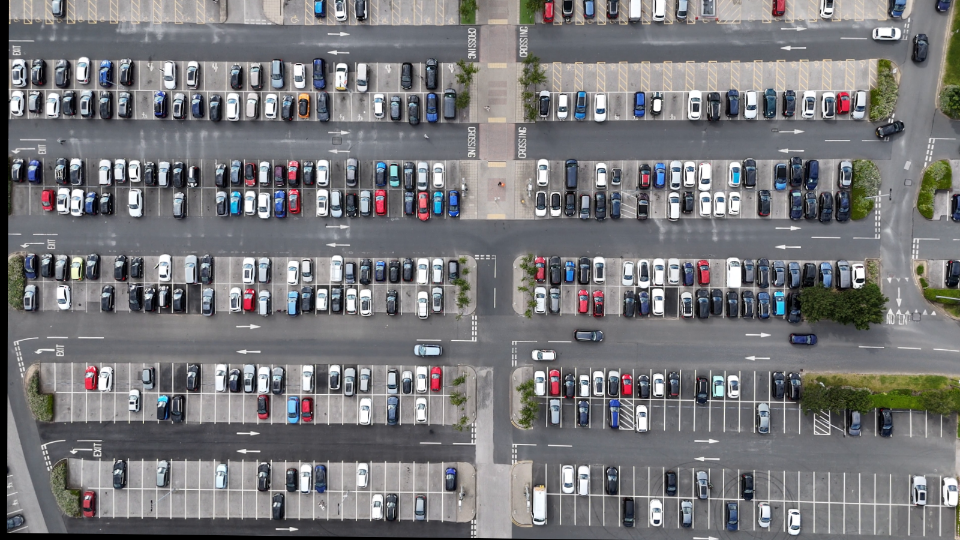

In [16]:
key_aligned, key_patches, key_labels = [], [], []
aligner = CameraAlignment(profile)
cap = cv2.VideoCapture(str(VIDEO_PATH))
try:
    for sec in key_seconds:
        target = round(sec * SOURCE_FPS)
        if not cap.set(cv2.CAP_PROP_POS_FRAMES, target):
            raise RuntimeError(f"Cannot seek to {sec}s")
        ok, original = cap.read()
        actual = cap.get(cv2.CAP_PROP_POS_FRAMES) - 1
        if not ok or abs(actual-target) > 1:
            raise RuntimeError(f"Failed to decode requested frame at {sec}s")
        frame = resize_frame(original, size)
        if not aligner.update(frame):
            raise RuntimeError(f"Alignment failed at {sec}s")
        aligned = cv2.warpPerspective(frame, aligner.h, size,
                                     flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP)
        masked = cv2.bitwise_and(aligned, aligned, mask=make_roi_mask(profile))
        patches = np.concatenate([b.patches(masked) for b in feature_batches])
        y = labels_for(slots, sec)
        key_aligned.append(aligned); key_patches.append(patches); key_labels.append(y)
        print(f"{sec:2d}s | empty={int((y==0).sum())}, occupied={int(y.sum())}")
finally:
    cap.release()
key_patches, key_labels = np.asarray(key_patches), np.asarray(key_labels)
X_original = np.array([describe_many(pp, FeatureBatch) for pp in key_patches])
X_augmented = np.array([describe_many(augment_patches(pp, CV_AUGMENTATIONS, 42+i), FeatureBatch)
                        for i, pp in enumerate(key_patches)])
print("Feature shapes:", X_original.shape, X_augmented.shape)
display(Image.fromarray(cv2.cvtColor(cv2.resize(key_aligned[-1], (960,540)), cv2.COLOR_BGR2RGB)))

## 8. 聯合搜尋 C 與 gamma
4 折交叉驗證各留出一個訓練時間點；29 秒不參與此步驟。主要依車格誤判數選參數，並同時記錄把有車誤判成空位的數量與空位計數誤差。

In [17]:
search_results, best_linear, best_rbf = grouped_search(
    X_original, X_augmented, key_labels, key_seconds,
    training_indices, C_GRID, GAMMA_FACTORS)
print("Selected linear:", best_linear)
print("Selected RBF:", best_rbf)
def show_table(rows):
    keys = list(rows[0])
    from html import escape
    head = "".join(f"<th>{escape(str(k))}</th>" for k in keys)
    body = "".join("<tr>"+"".join(f"<td>{escape(str(row[k]))}</td>" for k in keys)+"</tr>" for row in rows)
    display(HTML('<table style="border-collapse:collapse" border="1"><tr>'+head+'</tr>'+body+'</table>'))
show_table([{k:r[k] for k in ["kernel","C","gamma","cv_errors","cv_samples","cv_count_mae"]}
             for r in search_results])

linear C=0.1 gamma=None  CV errors=0/1916 count MAE=0.00  2.0s
linear C=1 gamma=None  CV errors=0/1916 count MAE=0.00  1.4s
linear C=10 gamma=None  CV errors=0/1916 count MAE=0.00  1.4s
rbf    C=0.1 gamma=0.00012578616352201257  CV errors=130/1916 count MAE=25.00  5.3s
rbf    C=0.1 gamma=0.0012578616352201257  CV errors=9/1916 count MAE=0.25  4.8s
rbf    C=0.1 gamma=0.012578616352201259  CV errors=750/1916 count MAE=187.50  8.7s
rbf    C=1 gamma=0.00012578616352201257  CV errors=9/1916 count MAE=1.25  2.7s
rbf    C=1 gamma=0.0012578616352201257  CV errors=1/1916 count MAE=0.25  3.2s
rbf    C=1 gamma=0.012578616352201259  CV errors=386/1916 count MAE=96.50  8.9s
rbf    C=10 gamma=0.00012578616352201257  CV errors=0/1916 count MAE=0.00  1.9s
rbf    C=10 gamma=0.0012578616352201257  CV errors=1/1916 count MAE=0.25  3.3s
rbf    C=10 gamma=0.012578616352201259  CV errors=386/1916 count MAE=96.50  8.9s
Selected linear: {'kernel': 'linear', 'C': 0.1, 'gamma': None, 'cv_errors': 0, 'cv_samples

kernel,C,gamma,cv_errors,cv_samples,cv_count_mae
linear,0.1,None,0,1916,0.0
linear,1.0,None,0,1916,0.0
linear,10.0,None,0,1916,0.0
rbf,0.1,0.00012578616352201257,130,1916,25.0
rbf,0.1,0.0012578616352201257,9,1916,0.25
rbf,0.1,0.012578616352201259,750,1916,187.5
rbf,1.0,0.00012578616352201257,9,1916,1.25
rbf,1.0,0.0012578616352201257,1,1916,0.25
rbf,1.0,0.012578616352201259,386,1916,96.5
rbf,10.0,0.00012578616352201257,0,1916,0.0


## 9. 留出畫面：公平比較
先在尚未用於調參或訓練的第 29 秒比較三者：原始線性基準、使用相同新增資料重訓的線性 SVM、使用相同資料的 RBF SVM。

表格中的 accuracy 是**該留出畫面的逐格分類準確率**，不是整支影片準確率。此步採原始二分類結果，不以「待確認」剔除困難樣本。

In [18]:
X_train = np.concatenate([X_augmented[i] for i in training_indices])
y_train = np.concatenate([np.repeat(key_labels[i], CV_AUGMENTATIONS) for i in training_indices])
mean_cv, scale_cv = standardizer(X_train)
X_test = X_original[holdout_index]
y_test = key_labels[holdout_index]
old_raw = (np.einsum("ij,j->i", X_test, np.asarray(profile["classifier"]["weights"], np.float32))
           + float(profile["classifier"]["bias"]))
holdout = {"original_linear": metrics(y_test, np.where(old_raw >= 0, 0, 1))}
holdout_predictions = {"original_linear": np.where(old_raw >= 0, 0, 1)}
for kind, parameters in [("retrained_linear", best_linear), ("rbf", best_rbf)]:
    kernel = "rbf" if kind == "rbf" else "linear"
    fitted = fit_svm(transform(X_train, mean_cv, scale_cv), y_train,
                     kernel, parameters["C"], parameters["gamma"])
    predictions = fitted.predict(transform(X_test, mean_cv, scale_cv))[1].ravel().astype(int)
    holdout[kind] = metrics(y_test, predictions)
    holdout_predictions[kind] = predictions
show_table([{"model":name, **row} for name,row in holdout.items()])
for name,predictions in holdout_predictions.items():
    print(name, "wrong bays:", [slots[i]["id"] for i in np.where(predictions!=y_test)[0]])
comparison_report = {"scope":"479 manually checked bays at 29s; same video/camera, before final refit",
    "best_rbf":best_rbf, "best_linear":best_linear, "holdout":holdout,
    "grid":search_results}
(OUTPUT_DIR/"parking_rbf_comparison.json").write_text(json.dumps(comparison_report,indent=2),encoding="utf-8")

model,samples,errors,accuracy,false_empty,false_occupied,true_empty,predicted_empty,empty_count_error
original_linear,479,0,1.0,0,0,193,193,0
retrained_linear,479,0,1.0,0,0,193,193,0
rbf,479,0,1.0,0,0,193,193,0


original_linear wrong bays: []
retrained_linear wrong bays: []
rbf wrong bays: []


4817

## 10. 用全部已核對畫面重訓最終 RBF 模型
因為目標是處理這支固定影片，完成獨立留出檢查後，最終輸出模型納入全部 5 個已核對時間點。請勿將這次重訓後對相同圖片的擬合成績當成新的測試成績。

RBF 模型保存完整支持向量與核參數，不會壓成單一線性權重；mean/std 也一起保存。

In [19]:
final_features = np.concatenate([describe_many(augment_patches(pp, FINAL_AUGMENTATIONS, 142+i), FeatureBatch)
                                 for i,pp in enumerate(key_patches)])
final_labels = np.concatenate([np.repeat(y, FINAL_AUGMENTATIONS) for y in key_labels])
final_mean, final_scale = standardizer(final_features)
final_svm = fit_svm(transform(final_features,final_mean,final_scale), final_labels,
                    "rbf", best_rbf["C"], best_rbf["gamma"])
MODEL_PATH = OUTPUT_DIR/"parking_rbf_model.xml"
SCALER_PATH = OUTPUT_DIR/"parking_rbf_scaler.json"
final_svm.save(str(MODEL_PATH))
SCALER_PATH.write_text(json.dumps({"mean":final_mean.tolist(),"scale":final_scale.tolist(),
    "C":best_rbf["C"],"gamma":best_rbf["gamma"]}),encoding="utf-8")
loaded_svm = cv2.ml.SVM_load(str(MODEL_PATH))
assert loaded_svm.getKernelType() == cv2.ml.SVM_RBF
check = transform(X_original[-1],final_mean,final_scale)
assert np.array_equal(final_svm.predict(check)[1],loaded_svm.predict(check)[1])
print("Saved/reloaded RBF model; support vectors:",len(loaded_svm.getSupportVectors()))

class RBFVacancyModel:
    def __init__(self, svm, mean, scale, batches):
        self.svm, self.mean, self.scale, self.batches = svm, mean, scale, batches
    def predict(self, aligned):
        X = np.concatenate([b.features(aligned) for b in self.batches])
        Z = transform(X,self.mean,self.scale)
        prediction = self.svm.predict(Z)[1].ravel().astype(np.int8)
        raw = self.svm.predict(Z,flags=cv2.ml.STAT_MODEL_RAW_OUTPUT)[1].ravel()
        return prediction,np.abs(raw)

rbf_model = RBFVacancyModel(loaded_svm,final_mean,final_scale,feature_batches)

Saved/reloaded RBF model; support vectors: 381


## 11. 狀態確認與 MP4 編碼
綠=確認空位、紅=有車、黃=低信心／狀態變化、青=霍夫候選直線、灰=ROI 外。每 3 幀重新分類、每 6 幀更新對齊與霍夫幾何，輸出保留每一幀與原始 FPS。



In [20]:
class StableOccupancy:
    def __init__(self, count, seconds=.3, margin=.45):
        self.seconds, self.margin = seconds, margin
        self.confirmed = np.full(count, UNKNOWN, np.int8)
        self.candidate = self.confirmed.copy()
        self.since = np.zeros(count, np.float64)
        self.initialized = False

    def update(self, prediction, confidence, visible, timestamp):
        raw = np.where((confidence >= self.margin) & visible, prediction, UNKNOWN).astype(np.int8)
        if not self.initialized:
            self.confirmed = raw.copy()
            self.candidate = raw.copy()
            self.since.fill(timestamp)
            self.initialized = True
            return raw
        changed = raw != self.candidate
        self.since[changed] = timestamp
        self.candidate = raw.copy()
        accept = (raw != UNKNOWN) & ((raw == self.confirmed)
                  | (timestamp - self.since >= self.seconds))
        self.confirmed[accept] = raw[accept]
        # Previously vacant bays stop contributing as soon as evidence changes.
        return np.where(accept, raw, UNKNOWN).astype(np.int8)

    def lost(self, timestamp):
        self.confirmed.fill(UNKNOWN)
        self.candidate.fill(UNKNOWN)
        self.since.fill(timestamp)
        return self.confirmed.copy()

class MP4Writer:
    def __init__(self, path, size, fps, use_ffmpeg=True):
        self.process = self.writer = self.error_file = None
        self.codec = None
        self.fps = fps
        self.frames_written = 0
        self.first_timestamp = None
        self.previous_frame = None
        if not path:
            return
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        executable = FFMPEG_EXE if use_ffmpeg else None
        if executable:
            self.error_file = tempfile.TemporaryFile(mode="w+b")
            cmd = [executable, "-hide_banner", "-loglevel", "error", "-y",
                   "-f", "rawvideo", "-pix_fmt", "bgr24", "-s", f"{size[0]}x{size[1]}",
                   "-r", str(fps), "-i", "pipe:0", "-an", "-c:v", "libx264",
                   "-preset", "veryfast", "-crf", "21", "-threads", "2",
                   "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(path)]
            self.process = subprocess.Popen(cmd, stdin=subprocess.PIPE, stderr=self.error_file)
            self.codec = "h264"
        else:
            self.writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
            if not self.writer.isOpened():
                raise RuntimeError(f"Cannot create output video: {path}")
            self.codec = "mp4v"

    def write(self, frame):
        if self.process:
            try:
                self.process.stdin.write(np.ascontiguousarray(frame).tobytes())
            except BrokenPipeError as exc:
                raise RuntimeError("FFmpeg stopped while encoding. Check available disk space and libx264.") from exc
        elif self.writer:
            self.writer.write(frame)
        self.frames_written += 1

    def write_timed(self, frame, timestamp):
        """For live input, repeat prior frames to preserve recording duration."""
        if self.first_timestamp is None:
            self.first_timestamp = timestamp
            self.write(frame)
        else:
            target = max(1, int((timestamp - self.first_timestamp) * self.fps) + 1)
            while self.frames_written + 1 < target:
                self.write(self.previous_frame)
            if self.frames_written < target:
                self.write(frame)
        self.previous_frame = frame

    def close(self):
        if self.writer:
            self.writer.release()
            self.writer = None
        if self.process:
            try:
                self.process.stdin.close()
            except BrokenPipeError:
                pass
            code = self.process.wait(timeout=60)
            self.process = None
            self.error_file.seek(0)
            error = self.error_file.read().decode("utf-8", "replace")
            self.error_file.close()
            if code:
                raise RuntimeError(f"Video encoder failed: {error[-1500:]}")

def annotate(frame, polygons, states, slots, timestamp, processing_fps, aligned, labels=False, hough_info=None):
    h, w = frame.shape[:2]
    scale = w / 1920
    footer = round(192 * scale / 2) * 2
    canvas = np.full((h + footer, w, 3), (26, 22, 17), np.uint8)
    scene = frame.copy()
    tint = scene.copy()
    colors = [GREEN if s == EMPTY else RED if s == OCCUPIED else AMBER for s in states]
    pixel_polygons = [np.rint(p).astype(np.int32) for p in polygons]
    for p, s, color in zip(pixel_polygons, states, colors):
        if s != OCCUPIED:
            cv2.fillConvexPoly(tint, p, color)
    cv2.addWeighted(tint, .15, scene, .85, 0, scene)
    for p, s, color, slot in zip(pixel_polygons, states, colors, slots):
        cv2.polylines(scene, [p], True, color, max(1, round(scale)), cv2.LINE_AA)
        if labels or s == EMPTY:
            center = p.mean(axis=0).astype(int)
            text = slot['id'].rsplit('-', 1)[-1]
            cv2.putText(scene, text, (int(center[0] - 6 * scale), int(center[1] + 3 * scale)),
                        cv2.FONT_HERSHEY_SIMPLEX, .27 * scale, (245, 250, 250),
                        max(1, round(scale)), cv2.LINE_AA)
    canvas[:h] = scene
    cv2.rectangle(canvas, (0, h), (w - 1, h + max(1, round(3 * scale))), GREEN, -1)

    def text(message, x, y, size=.55, color=(220, 227, 230), thickness=1):
        cv2.putText(canvas, str(message), (round(x * scale), h + round(y * scale)),
                    cv2.FONT_HERSHEY_SIMPLEX, size * scale, color,
                    max(1, round(thickness * scale)), cv2.LINE_AA)

    counts = [int((states == EMPTY).sum()), int((states == OCCUPIED).sum()),
              int((states == UNKNOWN).sum()), len(states)]
    for x, title, number, color in zip([36, 350, 664, 978],
            ["EMPTY", "OCCUPIED", "CHECKING", "MONITORED"], counts,
            [GREEN, RED, AMBER, (238, 240, 244)]):
        text(title, x, 36, .55, color)
        text(number, x, 112, 2.2, color, 3)
    text("MASK + HOUGH + RBF SVM", 1324, 36, .65, (242, 246, 248), 2)
    for j, (label, color) in enumerate([("EMPTY BAY", GREEN), ("VEHICLE PRESENT", RED), ("UNCERTAIN / CHANGING", AMBER)]):
        y = 68 + 25 * j
        cv2.rectangle(canvas, (round(1324 * scale), h + round((y - 11) * scale)),
                      (round(1337 * scale), h + round((y + 2) * scale)), color, -1)
        text(label, 1350, y, .46)
    status = "CAMERA ALIGNED" if aligned else "ALIGNMENT LOST - COUNTS WITHHELD"
    mins, secs = divmod(max(0, timestamp), 60)
    text(f"{int(mins):02d}:{secs:05.2f}   |   {status}   |   PROCESSING {processing_fps:.1f} FPS", 36, 160, .51)
    if hough_info:
        info=hough_info
        text(f"HOUGH {info['lines']} LINES | PAINT-SUPPORTED EMPTY {info['supported_empty']} | EDGE AREA {info['edge_area_pct']:.1f}%",
             978,160,.43,(163,190,197))
        text("Gray = outside ROI; cyan = candidate lines. Hough assists occupancy review; lines alone do not prove vacancy.",36,185,.40,(163,175,181))
    else:
        text("Calibrated visible bays only; cropped, hidden and hatched areas excluded.",978,160,.43,(163,175,181))
    return canvas

## 12. 完整影片推論
每個時間點的答案來自當下影像特徵與 RBF 模型。下列函式沒有讀取 `OVERRIDES` 或人工時間標籤，也不使用它們覆蓋分類結果。

同時輸出逐次計數 CSV 與處理統計 JSON。若解碼提前結束，程式會報錯，不會把短片冒充完整結果。

In [21]:
def render_rbf_video():
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    alignment = CameraAlignment(profile)
    stage = MaskedHoughPreprocessor(profile,mask_args)
    temporal = StableOccupancy(len(slots),STABILITY_SECONDS,UNKNOWN_MARGIN)
    polygons_ref = np.float32([s["polygon"] for s in slots])
    scene_height = round(OUTPUT_WIDTH*size[1]/size[0]/2)*2
    footer_height = round(192*(OUTPUT_WIDTH/1920)/2)*2
    out_size = (OUTPUT_WIDTH,scene_height+footer_height)
    display_scale = np.diag([OUTPUT_WIDTH/size[0],scene_height/size[1],1.])
    writer = MP4Writer(str(RESULT_PATH),out_size,SOURCE_FPS)
    states = np.full(len(slots),UNKNOWN,np.int8)
    index,updates,last_hough = 0,0,-1000000
    lost_frames, reviewed = 0,0
    started = time.perf_counter();last_print=started
    inference_ms=[]; key_result={};snapshots=[]
    csv_path = OUTPUT_DIR/"parking_rbf_counts.csv"
    try:
        with csv_path.open("w",newline="",encoding="utf-8") as f:
            out = csv.writer(f)
            out.writerow(["frame","time_s","empty","occupied","unknown","monitored","hough_lines"])
            while True:
                ok,original = cap.read()
                if not ok:break
                timestamp=index/SOURCE_FPS
                frame=resize_frame(original,size)
                if index%ALIGN_EVERY==0 or not alignment.ok:
                    alignment.update(frame)
                if not alignment.ok:
                    states=temporal.lost(timestamp);lost_frames+=1
                elif index%DETECT_EVERY==0:
                    tick=time.perf_counter()
                    aligned=cv2.warpPerspective(frame,alignment.h,size,
                        flags=cv2.INTER_LINEAR|cv2.WARP_INVERSE_MAP)
                    if index-last_hough>=HOUGH_EVERY:
                        stage.process(aligned);last_hough=index
                    masked=cv2.bitwise_and(aligned,aligned,mask=stage.roi_mask)
                    pred,confidence=rbf_model.predict(masked)
                    confidence=stage.review(pred,confidence)
                    reviewed+=int(stage.last_reviewed.sum())
                    projected=cv2.perspectiveTransform(polygons_ref.reshape(1,-1,2),alignment.h).reshape(-1,4,2)
                    visible=((projected[:,:,0]>=1).all(axis=1)&(projected[:,:,0]<=size[0]-2).all(axis=1)
                             &(projected[:,:,1]>=1).all(axis=1)&(projected[:,:,1]<=size[1]-2).all(axis=1))
                    states=temporal.update(pred,confidence,visible,timestamp)
                    counts={name:int((states==label).sum()) for name,label in
                            [("empty",EMPTY),("occupied",OCCUPIED),("unknown",UNKNOWN)]}
                    assert sum(counts.values())==len(slots)
                    out.writerow([index,round(timestamp,4),counts["empty"],counts["occupied"],counts["unknown"],len(slots),len(stage.lines)])
                    inference_ms.append((time.perf_counter()-tick)*1000);updates+=1
                h_display=display_scale@alignment.h
                polygons=cv2.perspectiveTransform(polygons_ref.reshape(1,-1,2),h_display).reshape(-1,4,2)
                scene=resize_frame(original,(OUTPUT_WIDTH,scene_height))
                scene=stage.paint_scene(scene,h_display,alignment.ok)
                elapsed=time.perf_counter()-started
                result=annotate(scene,polygons,states,slots,timestamp,(index+1)/max(elapsed,1e-6),
                                alignment.ok,False,stage.info(states))
                writer.write(result)
                if index in (0,round(15*SOURCE_FPS),SOURCE_FRAMES-1):
                    snapshots.append(result.copy())
                index+=1
                if time.perf_counter()-last_print>=5:
                    print(f"{index}/{SOURCE_FRAMES} frames | {timestamp:.2f}s | empty={int((states==EMPTY).sum())} "
                          f"occupied={int((states==OCCUPIED).sum())} checking={int((states==UNKNOWN).sum())}",flush=True)
                    last_print=time.perf_counter()
    finally:
        cap.release();writer.close()
    if index!=SOURCE_FRAMES:
        raise RuntimeError(f"Incomplete decode: {index}/{SOURCE_FRAMES} frames. Please use the complete original video.")
    elapsed=time.perf_counter()-started
    summary={"frames":index,"encoded_frames":writer.frames_written,"source_fps":SOURCE_FPS,
        "duration_seconds":index/SOURCE_FPS,"output_size":out_size,"codec":writer.codec,
        "processing_fps":index/elapsed,"processing_seconds":elapsed,
        "inference_updates":updates,"mean_inference_ms":float(np.mean(inference_ms)),
        "monitored_bays":len(slots),"alignment_lost_frames":lost_frames,
        "C":best_rbf["C"],"gamma":best_rbf["gamma"],
        "support_vectors":len(loaded_svm.getSupportVectors()),
        "unknown_margin":UNKNOWN_MARGIN,"hough_review_margin":mask_args.hough_review_margin,
        "hough_reviewed_updates":reviewed,"canny_work_fraction":stage.canny_pixels/stage.roi_mask.size,
        "final_counts":{name:int((states==label).sum()) for name,label in
                        [("empty",EMPTY),("occupied",OCCUPIED),("unknown",UNKNOWN)]}}
    (OUTPUT_DIR/"parking_rbf_run_stats.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
    return summary,snapshots

run_summary, result_snapshots = render_rbf_video()
print(json.dumps(run_summary,indent=2))
assert RESULT_PATH.is_file() and RESULT_PATH.stat().st_size>1000

13/910 frames | 0.40s | empty=185 occupied=294 checking=0
25/910 frames | 0.80s | empty=185 occupied=294 checking=0
40/910 frames | 1.30s | empty=185 occupied=293 checking=1
51/910 frames | 1.67s | empty=186 occupied=293 checking=0
64/910 frames | 2.10s | empty=186 occupied=293 checking=0
79/910 frames | 2.60s | empty=186 occupied=293 checking=0
89/910 frames | 2.94s | empty=185 occupied=292 checking=2
103/910 frames | 3.40s | empty=185 occupied=293 checking=1
116/910 frames | 3.84s | empty=186 occupied=292 checking=1
127/910 frames | 4.20s | empty=186 occupied=292 checking=1
141/910 frames | 4.67s | empty=187 occupied=292 checking=0
152/910 frames | 5.04s | empty=184 occupied=292 checking=3
164/910 frames | 5.44s | empty=187 occupied=292 checking=0
178/910 frames | 5.91s | empty=187 occupied=292 checking=0
187/910 frames | 6.21s | empty=187 occupied=291 checking=1
201/910 frames | 6.67s | empty=187 occupied=292 checking=0
215/910 frames | 7.14s | empty=187 occupied=291 checking=1
224/

## 13. 顯示結果與下載
MP4 在 Notebook 同一輸出資料夾。若使用 Colab 且影片無法預覽，可將 `EMBED_VIDEO` 改成 True，或直接下載檔案播放。

留出畫面比較是在最終重訓**之前**完成；最終影片使用納入所有已核對關鍵畫面的 RBF 模型，因此評估表不能當成整段輸出影片的全面準確率。

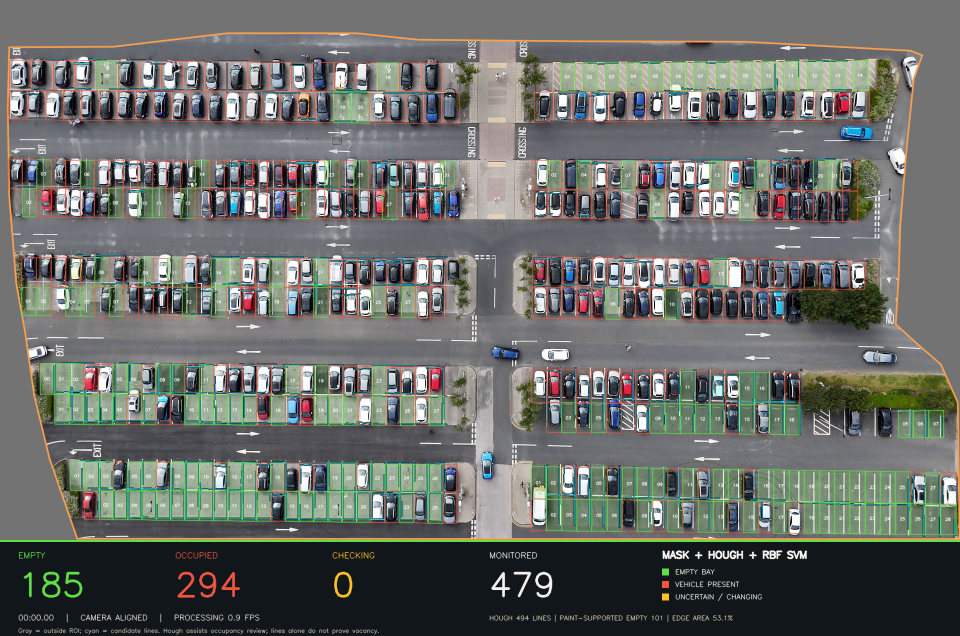

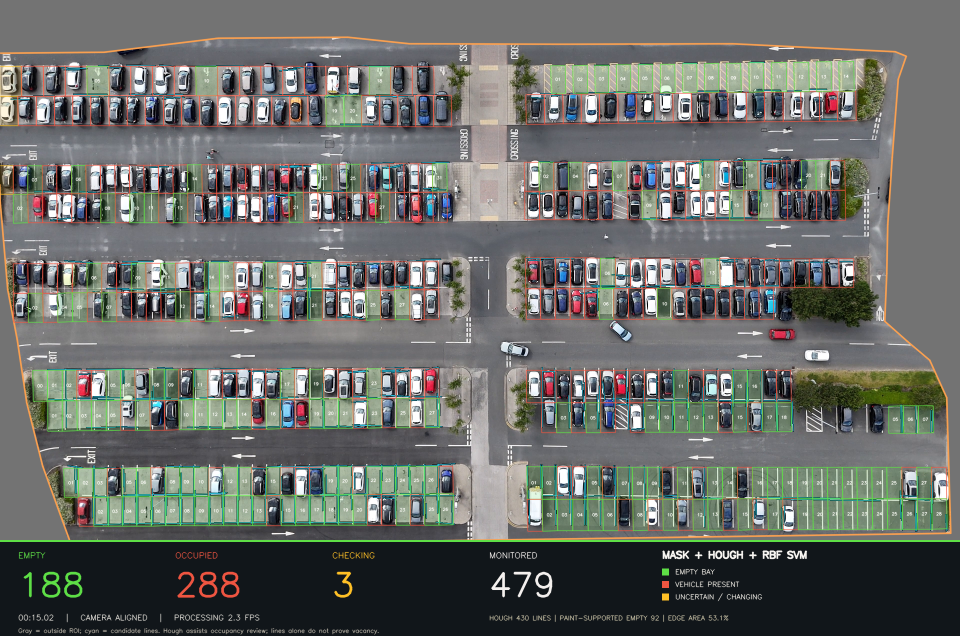

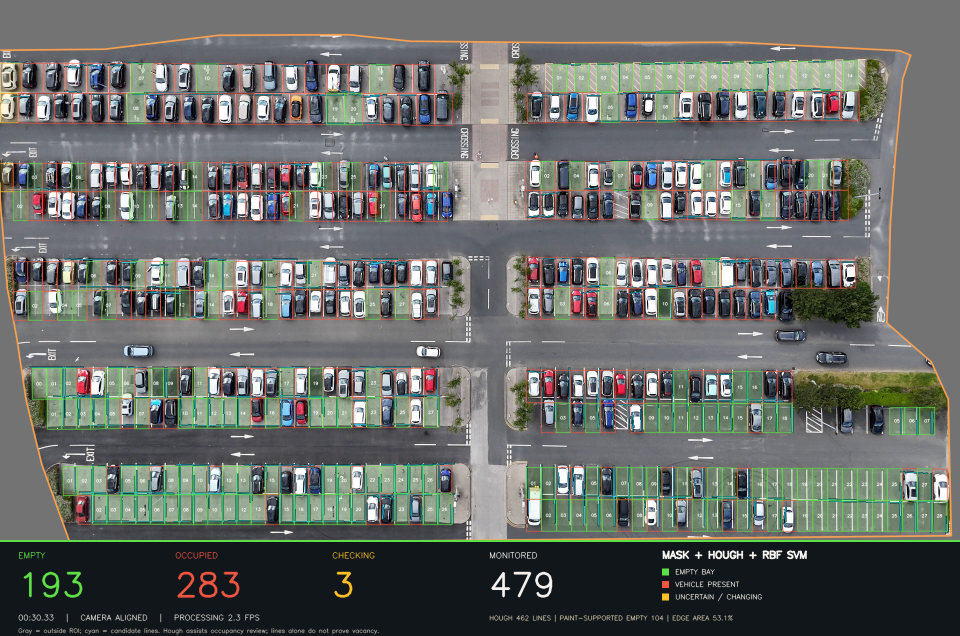

影片： parking_rbf_result.mp4
逐次計數：parking_rbf_counts.csv；比較：parking_rbf_comparison.json；完整 RBF 模型：parking_rbf_model.xml


/content/parking_rbf_result.mp4

In [22]:
relative_result = __import__("os").path.relpath(RESULT_PATH, Path.cwd())
display(Video(relative_result,embed=EMBED_VIDEO,width=960))
for frame in result_snapshots:
    thumbnail=cv2.resize(frame,(960,round(frame.shape[0]*960/frame.shape[1])))
    display(Image.fromarray(cv2.cvtColor(thumbnail,cv2.COLOR_BGR2RGB)))
print("影片：",RESULT_PATH.name)
print("逐次計數：parking_rbf_counts.csv；比較：parking_rbf_comparison.json；完整 RBF 模型：parking_rbf_model.xml")
from IPython.display import FileLink
display(FileLink(relative_result))

In [23]:
from google.colab import files
try:
    files.download(relative_result)
except Exception as e:
    print(f"下載失敗，請手動點擊左側檔案圖示進行下載。錯誤原因: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 參考
- [OpenCV SVM：C_SVC、RBF、模型儲存與載入](https://docs.opencv.org/4.x/d1/d2d/classcv_1_1ml_1_1SVM.html)
- [SVM 特徵尺度、C 與 gamma 的作用](https://scikit-learn.org/stable/modules/svm.html)
- [OpenCV HoughLinesP 參數](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html)

重新標定不同鏡位、或變更特徵提取方式後，需要重新建立樣本與訓練；本 Notebook 的人工標籤僅適用這支原始影片。